# Agrigine forecasts, 2026–2028

Forecasts the next three seasons for every county in California, Delaware, Iowa and Nebraska from 26 years of real
county records: crop yields, growing-season weather, drought, soil moisture and satellite greenness. Each forecast
comes with an 80% range and a score from ten years of held-out testing.

Rebuilt from `Predictive_Model.ipynb` and tuned for Apple Silicon:

| | Original | This notebook |
|---|---|---|
| Satellite and soil moisture | Invented by formula when missing | Real NASA MODIS greenness and NASA POWER soil moisture |
| Weather and drought | Whichever crop's season came first for each county | One fixed May–Sep window, computed from the daily and weekly records |
| What's forecast | Also soil properties, which never change | Only things that change year to year; soil is an input |
| Models | One neural network per target, checked on one split | Four candidates per target and horizon, checked on 10 held-out years; the winner is kept, even when it's the plain average |
| Daily 2026–2028 values | Synthetic curves with random noise | Not made: annual forecasts with a range |
| Speed | One model at a time on one core | All cores at once, on Apple's Accelerate math library |

**Run it** with the kernel *Agrigine model (sklearn 1.6.1)* from `notebooks/.venv`, or any Python 3.11+ with
`pip install "numpy<2.3" scikit-learn==1.6.1 pandas==2.2.3 pyarrow joblib threadpoolctl matplotlib`.
It reads the repo's `data/` folder and writes to `notebooks/forecasts/`.

In [1]:
import json, os, platform, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from joblib import Parallel, delayed
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from threadpoolctl import threadpool_limits

REPO = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
DATA = REPO / 'data'
OUT = REPO / 'notebooks' / 'forecasts'
OUT.mkdir(exist_ok=True)

FIRST_YEAR, ORIGIN = 2000, 2025      # the records run 2000–2025; forecasts start from 2025
HORIZONS = (1, 2, 3)                 # 2026, 2027, 2028
TEST_YEARS = range(2016, 2026)       # backtest: each of these years is predicted only from the years before it
SEASON = (5, 9)                      # county-wide measures use one fixed window, May through September

# Apple Silicon: the models are small, so the CPU cores beat the GPU (moving data to it costs more than it saves).
# Many models train at once, one per core, each held to one thread so they don't compete for cores.
N_JOBS = os.cpu_count()
BLAS = np.show_config(mode='dicts')['Build Dependencies']['blas']['name']
print(f'{platform.system()} {platform.machine()} · {N_JOBS} cores · NumPy {np.__version__} on {BLAS} · scikit-learn {sklearn.__version__}')
if platform.machine() == 'arm64' and BLAS != 'accelerate':
    print('Tip: NumPy 2.x wheels on macOS 14+ use Apple Accelerate, which is faster on this chip.')

Darwin arm64 · 8 cores · NumPy 2.2.6 on accelerate · scikit-learn 1.6.1


## 1. Real data, one row per county and year

Everything comes from the repo's `data/` folder. County-wide measures cover all 253 counties; yields cover the 230
counties with NASS records. Missing values stay missing: the models handle gaps instead of having them made up.

In [2]:
t0 = time.time()
geo = json.loads((DATA / 'counties.geojson').read_text())
places = pd.DataFrame([{'fips': f['id'], 'county': f['properties']['county_name'].replace(' County', ''), 'state': f['properties']['state_alpha']}
                       for f in geo['features']])
in_season = lambda d: d.dt.month.between(*SEASON) & d.dt.year.ge(FIRST_YEAR)

# Weather (NOAA ACIS daily): rain, average temperature, days at 35 °C+, growing degree days (base 10 °C, cap 30 °C)
wx = pd.read_parquet(DATA / 'processed/acis/weather_daily.parquet', columns=['fips', 'date', 'pcpn_mm', 'tmax_c', 'tmin_c'])
wx = wx[in_season(wx.date)].assign(year=lambda d: d.date.dt.year, tavg=lambda d: (d.tmax_c + d.tmin_c) / 2,
                                   hot=lambda d: d.tmax_c.ge(35),
                                   gdd=lambda d: ((d.tmax_c.clip(upper=30) + d.tmin_c.clip(lower=10)) / 2 - 10).clip(lower=0))
weather = wx.groupby(['fips', 'year']).agg(rain_mm=('pcpn_mm', 'sum'), tavg_c=('tavg', 'mean'), heat_days=('hot', 'sum'), gdd=('gdd', 'sum')).reset_index()

# Drought (U.S. Drought Monitor weekly): mean DSCI and weeks with severe drought (D2+) on more than 1% of the county
dr = pd.read_parquet(DATA / 'processed/drought/drought_weekly.parquet', columns=['fips', 'map_date', 'D2', 'D3', 'D4', 'dsci'])
dr = dr[in_season(dr.map_date)].assign(year=lambda d: d.map_date.dt.year, d2=lambda d: (d.D2 + d.D3 + d.D4).gt(1))
drought = dr.groupby(['fips', 'year']).agg(dsci=('dsci', 'mean'), d2_weeks=('d2', 'sum')).reset_index()

# Soil moisture and air dryness (NASA POWER daily)
pw = pd.concat(pd.read_parquet(p, columns=['fips', 'date', 'soil_wetness_pct', 'vpd_kpa']) for p in sorted((DATA / 'processed/power/daily').glob('*.parquet')))
pw = pw[in_season(pw.date)].assign(year=lambda d: d.date.dt.year)
water = pw.groupby(['fips', 'year']).agg(soil_wetness=('soil_wetness_pct', 'mean'), vpd=('vpd_kpa', 'mean')).reset_index()

# Satellite greenness (NASA MODIS) and soil properties (NRCS SSURGO), which don't change
sat = pd.read_parquet(DATA / 'processed/modis/modis_ndvi_county.parquet', columns=['fips', 'year', 'ndvi_max', 'evi_mean'])
soil = pd.read_parquet(DATA / 'processed/soil/soil_county.parquet', columns=['fips', 'aws_100cm_mm', 'droughty_pct'])

grid = pd.MultiIndex.from_product([places.fips, range(FIRST_YEAR, ORIGIN + 1)], names=['fips', 'year']).to_frame(index=False)
county = grid.merge(places, on='fips')
for part in (weather, drought, water, sat):
    county = county.merge(part, on=['fips', 'year'], how='left')
county = county.merge(soil, on='fips', how='left')

# Yields (USDA NASS via the master dataset): only NASS-reported yields count
master = pd.read_parquet(DATA / 'master_dataset.parquet', columns=['fips', 'crop', 'year', 'yield_per_acre', 'yield_status', 'nccpi_crop'])
master['fips'] = master.fips.astype(str)
crops = master.assign(yield_bu=master.yield_per_acre.where(master.yield_status.eq('reported'))).drop(columns=['yield_per_acre', 'yield_status'])
crops = crops.merge(county, on=['fips', 'year'], how='left')

print(f'Loaded in {time.time() - t0:.1f} s: {county.fips.nunique()} counties × {county.year.nunique()} years; '
      f'{crops.yield_bu.notna().sum():,} reported yields')
county.drop(columns=['fips', 'county', 'state', 'year']).describe().T[['count', 'mean', 'min', 'max']].round(2)

Loaded in 0.5 s: 253 counties × 26 years; 11,639 reported yields


,count,mean,min,max
rain_mm,6578.0,388.04,0.00,1260.63
tavg_c,6578.0,20.32,13.69,30.66
heat_days,6578.0,10.38,0.00,146.00
gdd,6578.0,1564.60,793.94,2457.66
dsci,6578.0,99.41,0.00,500.00
d2_weeks,6578.0,4.52,0.00,22.00
soil_wetness,6578.0,47.80,15.97,87.16
vpd,6578.0,1.16,0.22,4.17
ndvi_max,5980.0,0.78,0.16,0.93
evi_mean,5980.0,0.27,0.08,0.41


## 2. What gets forecast, and from what

Each forecast is made at the end of a season (the *origin*, year T) for 1, 2 and 3 seasons ahead. A model only sees
what was known at T: the target's last three values, recent conditions (rain, heat, drought, soil moisture,
greenness), the place's own average so far, soil properties and the state.

In [3]:
# id, category, label, unit, column, crop (None = county-wide)
TARGETS = [
    ('yield_corn',     'crops',          'Corn yield',                          'bu/ac', 'yield_bu', 'CORN'),
    ('yield_soybeans', 'crops',          'Soybean yield',                       'bu/ac', 'yield_bu', 'SOYBEANS'),
    ('yield_wheat',    'crops',          'Winter wheat yield',                  'bu/ac', 'yield_bu', 'WHEAT'),
    ('yield_sorghum',  'crops',          'Sorghum yield',                       'bu/ac', 'yield_bu', 'SORGHUM'),
    ('rain_mm',        'weather',        'Rain, May–Sep',                       'mm',    'rain_mm', None),
    ('tavg_c',         'weather',        'Average temperature, May–Sep',        '°C',    'tavg_c', None),
    ('heat_days',      'weather',        'Days at 35 °C or hotter, May–Sep',    'days',  'heat_days', None),
    ('gdd',            'weather',        'Growing degree days, May–Sep',        'GDD',   'gdd', None),
    ('dsci',           'drought',        'Drought intensity (DSCI), May–Sep',   '0–500', 'dsci', None),
    ('d2_weeks',       'drought',        'Weeks in severe drought, May–Sep',    'weeks', 'd2_weeks', None),
    ('soil_wetness',   'land_and_water', 'Root-zone soil moisture, May–Sep',    '% wet', 'soil_wetness', None),
    ('ndvi_max',       'satellite',      'Peak greenness (NDVI)',               'NDVI',  'ndvi_max', None),
    ('evi_mean',       'satellite',      'Average greenness (EVI)',             'EVI',   'evi_mean', None),
]
DRIVERS = ['rain_mm', 'tavg_c', 'heat_days', 'dsci', 'soil_wetness', 'ndvi_max']
STATIC = ['aws_100cm_mm', 'droughty_pct']
NOT_FEATURES = {'fips', 'crop', 'county', 'state', 'target_year', 'y'}


def supervised(frame, keys, target, horizon, extra=()):
    # One row per place and origin year T, with the answer at T + horizon.
    f = frame.sort_values(keys + ['year']).copy()
    g = f.groupby(keys, sort=False)[target]
    f['clim'] = g.transform(lambda s: s.expanding().mean())         # the place's average through T
    f['n_obs'] = g.transform(lambda s: s.notna().cumsum())          # how many years that average rests on
    rows = f[keys + ['county', 'state', 'year', 'clim', 'n_obs'] + STATIC + list(extra)].rename(columns={'year': 'origin'})
    for lag in (0, 1, 2):
        cols = list(dict.fromkeys([target] + (DRIVERS if lag < 2 else [])))
        prev = f[keys + ['year'] + cols].copy()
        prev['origin'] = prev.pop('year') + lag
        rows = rows.merge(prev.rename(columns={c: f'{c}_t{lag}' for c in cols}), on=keys + ['origin'], how='left')
    rows['target_year'] = rows.origin + horizon
    answer = f[keys + ['year', target]].rename(columns={'year': 'target_year', target: 'y'})
    rows = rows.merge(answer, on=keys + ['target_year'], how='left')
    numeric = [c for c in rows.columns if c not in NOT_FEATURES]
    rows[numeric] = rows[numeric].astype('float32')                   # half the memory traffic; plenty of precision
    return rows, numeric


TABLES = {}
for tid, cat, label, unit, col, crop in TARGETS:
    frame = crops[crops.crop.eq(crop)] if crop else county
    keys = ['fips', 'crop'] if crop else ['fips']
    for h in HORIZONS:
        TABLES[tid, h] = supervised(frame, keys, col, h, extra=['nccpi_crop'] if crop else [])
rows, numeric = TABLES['yield_corn', 1]
print(f'{len(TABLES)} training tables. Corn, 1 year ahead: {rows.y.notna().sum():,} rows with an answer, {len(numeric)} inputs')

39 training tables. Corn, 1 year ahead: 4,661 rows with an answer, 21 inputs


## 3. Four candidates, ten held-out years

For every target and horizon, four models compete:

- **Place average**: the county's own average so far. The bar every model has to clear.
- **County trend**: the original notebook's baseline, a shared trend plus a level for each county.
- **Gradient boosting**: trees, which suit small tabular data and handle gaps natively.
- **Neural network**: the original's two-layer network, now with the place average as an input instead of 253
  county switches.

Each of 2016–2025 is predicted using only seasons that had finished by the forecast's origin. That's 1,500+ model
fits, spread across all cores.

In [4]:
MODELS = ['place_average', 'county_trend', 'gradient_boosting', 'neural_net']
LABEL = {'place_average': 'Place average', 'county_trend': 'County trend', 'gradient_boosting': 'Gradient boosting', 'neural_net': 'Neural network'}


def make_model(name, numeric):
    if name == 'county_trend':
        pre = ColumnTransformer([('year', 'passthrough', ['target_year']), ('place', OneHotEncoder(handle_unknown='ignore'), ['fips'])])
        return make_pipeline(pre, Ridge(alpha=10.0))
    if name == 'gradient_boosting':
        pre = ColumnTransformer([('num', 'passthrough', numeric),
                                 ('state', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ['state'])])
        trees = HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=30,
                                              l2_regularization=1.0, categorical_features=[len(numeric)], random_state=0)
        return make_pipeline(pre, trees)
    if name == 'neural_net':
        pre = ColumnTransformer([('num', make_pipeline(SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True), StandardScaler()), numeric),
                                 ('state', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['state'])])
        net = MLPRegressor(hidden_layer_sizes=(32, 16), alpha=2.0, max_iter=600, early_stopping=True, n_iter_no_change=20, random_state=0)
        return TransformedTargetRegressor(regressor=make_pipeline(pre, net), transformer=StandardScaler())
    raise ValueError(name)


def fit_predict(name, train, test, numeric, keep=False):
    # Runs inside a worker process: one thread, quiet about early-stopping notices.
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        if name == 'place_average':
            return test['clim'].fillna(train['y'].mean()).to_numpy(dtype=float), None
        model = make_model(name, numeric).fit(train, train['y'])
        return model.predict(test), (model if keep else None)


def backtest_job(tid, h, year, name, train, test, numeric):
    pred, _ = fit_predict(name, train, test, numeric)
    return {'tid': tid, 'h': h, 'year': year, 'model': name, 'resid': test['y'].to_numpy(dtype=float) - pred}


jobs = []
for (tid, h), (rows, numeric) in TABLES.items():
    known = rows[rows.y.notna()]
    for year in TEST_YEARS:
        train, test = known[known.target_year.le(year - h)], known[known.target_year.eq(year)]
        if len(train) >= 50 and len(test) >= 5:
            jobs += [delayed(backtest_job)(tid, h, year, m, train, test, numeric) for m in MODELS]

t0 = time.time()
results = Parallel(n_jobs=N_JOBS)(jobs)
took = time.time() - t0
print(f'{len(jobs):,} backtest fits in {took:.0f} s on {N_JOBS} cores ({len(jobs) / took:.1f} fits per second)')

1,536 backtest fits in 67 s on 8 cores (22.9 fits per second)


## 4. Scores: does anything beat the place's own average?

**Skill** compares each model's error with the place average's: +20% means 20% smaller errors, 0% means no better,
and below zero means worse. For each target and horizon, the winner is the model with the smallest error over all
ten test years, as long as it beats the place average by at least 5%. Smaller gains are within the noise, so then
the place average is used, and the forecast says so.

In [5]:
pooled = (pd.DataFrame(results).groupby(['tid', 'h', 'model'])['resid']
          .apply(lambda r: np.concatenate(list(r))).rename('resid').reset_index())
pooled['mae'] = pooled.resid.apply(lambda r: float(np.mean(np.abs(r))))
pooled['n'] = pooled.resid.apply(len)
base = pooled[pooled.model.eq('place_average')].set_index(['tid', 'h']).mae
pooled['skill'] = 1 - pooled.mae / pooled.set_index(['tid', 'h']).index.map(base)

MIN_GAIN = 0.05   # a model has to cut the place average's error by 5% to be trusted over it
eligible = pooled[pooled.model.eq('place_average') | pooled.skill.ge(MIN_GAIN)]
winners = eligible.loc[eligible.groupby(['tid', 'h']).mae.idxmin()].set_index(['tid', 'h'])
winners['low_q'] = winners.resid.apply(lambda r: float(np.quantile(r, 0.10)))     # 80% range from the winner's own test errors
winners['high_q'] = winners.resid.apply(lambda r: float(np.quantile(r, 0.90)))

meta = {t[0]: dict(zip(['category', 'label', 'unit', 'column', 'crop'], t[1:])) for t in TARGETS}
table = pooled.pivot_table(index=['tid', 'h'], columns='model', values='mae').round(3)[MODELS]
table.columns = [LABEL[m] for m in MODELS]
table['Winner'] = [LABEL[winners.loc[i, 'model']] for i in table.index]
table['Skill vs average'] = [f"{winners.loc[i, 'skill']:+.0%}" for i in table.index]
table.index = [f"{meta[t]['label']} (+{h} yr)" for t, h in table.index]
table

,Place average,County trend,Gradient boosting,Neural network,Winner,Skill vs average
"Weeks in severe drought, May–Sep (+1 yr)",5.912,6.434,5.629,6.310,Place average,+0%
"Weeks in severe drought, May–Sep (+2 yr)",5.989,6.681,7.659,8.685,Place average,+0%
"Weeks in severe drought, May–Sep (+3 yr)",5.981,6.999,7.056,5.765,Place average,+0%
"Drought intensity (DSCI), May–Sep (+1 yr)",90.011,95.881,97.268,104.446,Place average,+0%
"Drought intensity (DSCI), May–Sep (+2 yr)",91.631,100.409,118.297,160.777,Place average,+0%
"Drought intensity (DSCI), May–Sep (+3 yr)",91.820,106.085,119.331,124.578,Place average,+0%
Average greenness (EVI) (+1 yr),0.013,0.016,0.010,0.011,Gradient boosting,+18%
Average greenness (EVI) (+2 yr),0.013,0.017,0.013,0.013,Place average,+0%
Average greenness (EVI) (+3 yr),0.013,0.018,0.013,0.014,Place average,+0%
"Growing degree days, May–Sep (+1 yr)",61.664,65.963,72.716,70.292,Place average,+0%


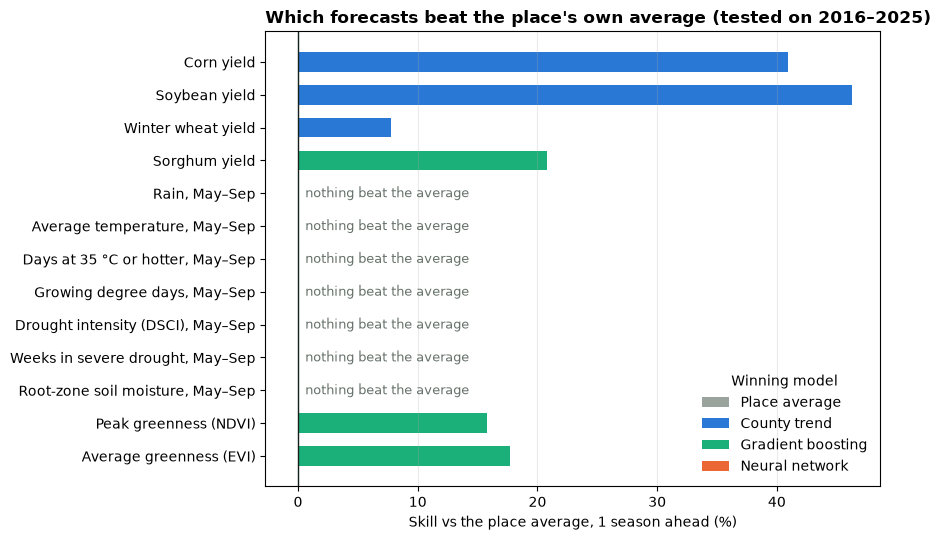

In [6]:
# Skill of the winning model one season ahead, by target
one = winners.xs(1, level='h').reindex([t[0] for t in TARGETS])
colors = {'place_average': '#9AA39C', 'county_trend': '#2A78D6', 'gradient_boosting': '#1BAF7A', 'neural_net': '#EB6834'}
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh([meta[t]['label'] for t in one.index], one.skill * 100, color=[colors[m] for m in one.model], height=0.6)
ax.axvline(0, color='#14201A', lw=1)
for y, (t, w) in enumerate(one.iterrows()):
    if w.model == 'place_average':
        ax.text(0.6, y, 'nothing beat the average', va='center', fontsize=9, color='#66716A')
ax.invert_yaxis()
ax.set_xlabel('Skill vs the place average, 1 season ahead (%)')
ax.set_title('Which forecasts beat the place\'s own average (tested on 2016–2025)', loc='left', fontsize=12, fontweight='bold')
for m, c in colors.items():
    ax.bar(0, 0, color=c, label=LABEL[m])
ax.legend(title='Winning model', frameon=False, loc='lower right')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Forecasts for 2026, 2027 and 2028

Each winning model is refit on every season through 2025 and run from 2025. The range is the winner's 10th to 90th
percentile error in testing, so about 8 in 10 outcomes should land inside it. Places without at least five past
values get no forecast.

In [7]:
def final_job(tid, h, name, train, current, numeric):
    pred, model = fit_predict(name, train, current, numeric, keep=True)
    return tid, h, pred, model


finals = []
for (tid, h), (rows, numeric) in TABLES.items():
    current = rows[rows.origin.eq(ORIGIN) & rows.n_obs.ge(5)]
    finals.append(delayed(final_job)(tid, h, winners.loc[(tid, h), 'model'], rows[rows.y.notna()], current, numeric))

t0 = time.time()
fitted = Parallel(n_jobs=N_JOBS)(finals)
print(f'{len(fitted)} final models in {time.time() - t0:.1f} s')

NONNEG = {'yield_bu', 'rain_mm', 'heat_days', 'gdd', 'dsci', 'd2_weeks', 'soil_wetness', 'ndvi_max', 'evi_mean'}
parts, models = [], {}
for tid, h, pred, model in fitted:
    rows, numeric = TABLES[tid, h]
    current = rows[rows.origin.eq(ORIGIN) & rows.n_obs.ge(5)]
    w, m = winners.loc[(tid, h)], meta[tid]
    lo, hi = pred + w.low_q, pred + w.high_q
    if m['column'] in NONNEG:
        pred, lo, hi = np.clip(pred, 0, None), np.clip(lo, 0, None), np.clip(hi, 0, None)
    parts.append(pd.DataFrame({
        'target': tid, 'category': m['category'], 'label': m['label'], 'unit': m['unit'], 'crop': m['crop'],
        'fips': current.fips.to_numpy(), 'county': current.county.to_numpy(), 'state': current.state.to_numpy(),
        'year': ORIGIN + h, 'horizon': h, 'forecast': pred, 'low': lo, 'high': hi,
        'model': w.model, 'skill_vs_average': w.skill,
    }))
    models[tid, h] = {'model': model, 'kind': w.model, 'inputs': numeric, 'range': (w.low_q, w.high_q)}
forecasts = pd.concat(parts, ignore_index=True)
print(f'{len(forecasts):,} forecasts: {forecasts.fips.nunique()} counties × {forecasts.target.nunique()} targets × {len(HORIZONS)} years')
forecasts[forecasts.fips.eq('19153')].pivot_table(index='label', columns='year', values='forecast').round(1)

39 final models in 0.6 s
8,385 forecasts: 253 counties × 13 targets × 3 years


year,2026,2027,2028
label,,,
Average greenness (EVI),0.3,0.3,0.3
"Average temperature, May–Sep",20.5,20.5,20.5
Corn yield,202.9,204.5,204.9
"Days at 35 °C or hotter, May–Sep",4.0,4.0,4.0
"Drought intensity (DSCI), May–Sep",60.2,60.2,60.2
"Growing degree days, May–Sep",1608.7,1670.5,1608.7
Peak greenness (NDVI),0.8,0.8,0.8
"Rain, May–Sep",561.4,561.4,561.4
"Root-zone soil moisture, May–Sep",52.3,52.3,52.3


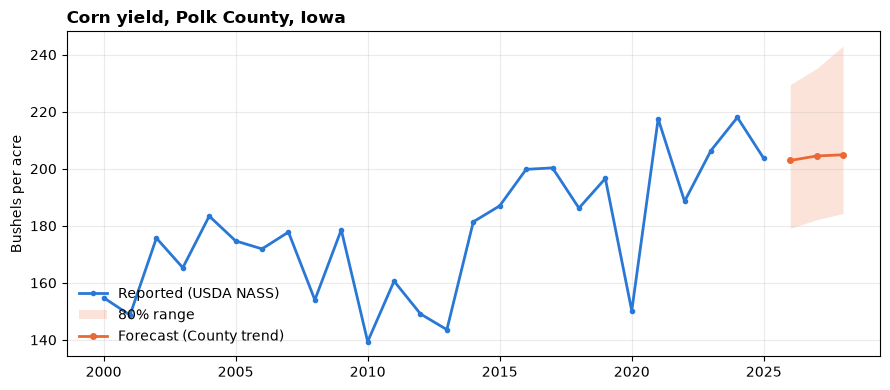

In [8]:
# Polk County, Iowa: corn yield history and the three-year forecast with its 80% range
hist = crops[crops.fips.eq('19153') & crops.crop.eq('CORN')].sort_values('year')
fc = forecasts[forecasts.fips.eq('19153') & forecasts.target.eq('yield_corn')].sort_values('year')
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hist.year, hist.yield_bu, color='#2A78D6', lw=2, marker='o', ms=3, label='Reported (USDA NASS)')
ax.fill_between(fc.year, fc.low, fc.high, color='#EB6834', alpha=0.18, lw=0, label='80% range')
ax.plot(fc.year, fc.forecast, color='#EB6834', lw=2, marker='o', ms=4, label=f'Forecast ({LABEL[fc.model.iloc[0]]})')
ax.set_ylabel('Bushels per acre')
ax.set_title('Corn yield, Polk County, Iowa', loc='left', fontsize=12, fontweight='bold')
ax.legend(frameon=False, loc='lower left')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Save

- `forecasts/forecasts_2026_2028.csv`: every forecast with its range, winning model and skill.
- `forecasts/backtest_scores.csv`: every candidate's test error and skill, by target and horizon.
- `forecasts/forecast_models.joblib`: the winning models, with their input columns and ranges (scikit-learn 1.6.1).
- `forecasts/forecasts.json`: a compact copy for the Agrigine app.

In [9]:
forecasts.round(4).to_csv(OUT / 'forecasts_2026_2028.csv', index=False)
pooled.drop(columns='resid').round(4).to_csv(OUT / 'backtest_scores.csv', index=False)
joblib.dump({'models': models, 'targets': meta, 'origin': ORIGIN, 'sklearn': sklearn.__version__}, OUT / 'forecast_models.joblib', compress=3)

app = {
    'origin': ORIGIN, 'years': [ORIGIN + h for h in HORIZONS], 'tested_on': [min(TEST_YEARS), max(TEST_YEARS)],
    'targets': {tid: {**meta[tid], 'model': {str(h): winners.loc[(tid, h), 'model'] for h in HORIZONS},
                      'skill': {str(h): round(float(winners.loc[(tid, h), 'skill']), 3) for h in HORIZONS}} for tid in meta},
    'counties': {},
}
for (fips, tid), g in forecasts.sort_values('year').groupby(['fips', 'target']):
    app['counties'].setdefault(fips, {})[tid] = [[int(r.year), round(float(r.forecast), 2), round(float(r.low), 2), round(float(r.high), 2)] for r in g.itertuples()]
(OUT / 'forecasts.json').write_text(json.dumps(app, separators=(',', ':')))

for p in sorted(OUT.iterdir()):
    print(f'{p.name:<28} {p.stat().st_size / 1e6:6.2f} MB')

backtest_scores.csv            0.01 MB
forecast_models.joblib         1.18 MB
forecasts.json                 0.25 MB
forecasts_2026_2028.csv        1.00 MB
